# $\textbf{Projects Practice}$

## Time Series Analysis

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

In [ ]:
stock_data =pd.read_csv('stock_data.csv' , parse_dates = True , index_col = 'Date')
stock_data.head()

In [ ]:
stock_data.drop(columns = {'Unnamed: 0'} , inplace = True)

In [ ]:
stock_data['High'].plot(kind = 'line' , figsize =(12 ,5))
sns.despine()

### Resampling Data

In [ ]:
#stock_data['month'] = stock_data.index.month
#stock_data['year'] = stock_data.index.year
#stock_data['year_month']=  stock_data['year']+'-'+stock_data['month']

In [ ]:
resampled_df = stock_data.resample('M').mean()
resampled_df

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

In [ ]:
resampled_df['High'].plot(kind = 'line' , figsize =(12 ,4))
sns.despine()

### Detecting Autocorrelation

In [ ]:
plot_acf(stock_data['High']  , lags = 40)
plt.show()

- There is seasonality

### Testing Stationarity Using Dickey Fuller Test

Null Hypothesis = 1(No stationarity)\
Alternative Hypothesis < <1(stationarity) 


In [ ]:
results = adfuller(stock_data['High'])
print('ADF Statistic:' , results[0])
print('p_value:' , results[1])
print('Critical Statistic:' , results[2])

### Differencing To Archive Stationarity

In [ ]:
stock_data['diff_high'] = stock_data['High'].diff()

In [ ]:
stock_data.dropna(inplace = True)

In [ ]:
sto

In [ ]:
stock_data['High'].plot(kind = 'line')
stock_data['diff_high'].plot(kind = 'line')

### Smoothing

In [ ]:
stock_data['Smoothed_high'] = stock_data['High'].rolling(window = 120).mean()

In [ ]:
stock_data

In [ ]:
plt.figure(figsize = (12,5))
stock_data['High'].plot(kind = 'line')
stock_data['Smoothed_high'].plot(kind = 'line' , linestyle = '--')

### Testing Diiferenced

In [ ]:
results1 = adfuller(stock_data['diff_high'])
print('ADF Statistic:' , results1[0])
print('p_value:' , results1[1])
print('Critical Statistic:' , results1[2])

- Now its stationary

In [ ]:
plot_acf(stock_data['diff_high']  , lags = 40)
plt.show()

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

In [ ]:
plot_pacf(stock_data['diff_high']  , lags = 40)
plt.show()

## ARIMA

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
data_arima = stock_data[['High' , 'diff_high']]

In [ ]:
arima = ARIMA(data_arima['diff_high'] , order = (1,1,1))
arima_model = arima.fit()
arima_model.summary()


In [ ]:
pacf_plot = plot_pacf(arima_model.resid , lags=30)
#acf_plot =plot_acf(arima_model.resid , lags=30)
print(pacf_plot)

In [ ]:
plt.plot(data_arima['diff_high'] )
plt.plot(arima_model.fittedvalues , color = 'red')
plt.title("RSS: %.4f"% sum((arima_model.fittedvalues-data_arima['High'])**2))

In [ ]:
arima_data

In [ ]:
arima_model.predict(start = 2000 , end = 3200).plot(kind = 'line' , figsize = (12,5))


In [ ]:
data_arima.count()

In [ ]:
forecast_30 = arima_model.forecast(steps =30)
forecast_30

In [ ]:
arima1 = ARIMA(data_arima['High'] , order = (1,1,1))
arima_model1 = arima1.fit()
arima_model1.summary()

In [ ]:
arima_model1.predict(start = 0 , end = 3218).plot(kind = 'line' , figsize = (12,5))

In [ ]:
a

# Predicting Using XGBoost

In [ ]:
pip install XGBoost


In [ ]:
pip install xgboost 

In [ ]:
import xgboost as xgb

# LINEAR REGRESSION

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [19]:
data  = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Sales.csv")
data1 = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Products.csv")
data.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD


In [25]:
mydata = data.merge(data1 , on = 'ProductKey' , how = 'left')
mydata

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,$31.27,$68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,$141.47,$427.00,402,Digital SLR Cameras,4,Cameras and camcorders
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,$220.64,$665.94,803,Microwaves,8,Home Appliances
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,$148.08,$322.00,402,Digital SLR Cameras,4,Cameras and camcorders
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,$166.20,$326.00,301,Laptops,3,Computers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62879,2243030,1,2/20/2021,NaN,1216913,43,632,3,USD,WWI Screen 85in E1010 White,Wide World Importers,White,$70.87,$139.00,305,Projectors & Screens,3,Computers
62880,2243031,1,2/20/2021,2/24/2021,511229,0,98,4,EUR,WWI Wireless Bluetooth Stereo Headphones M170 ...,Wide World Importers,Silver,$55.18,$120.00,106,Bluetooth Headphones,1,Audio
62881,2243032,1,2/20/2021,2/23/2021,331277,0,1613,2,CAD,SV DVD 7-Inch Player Portable E200 White,Southridge Video,White,$56.08,$109.99,602,Movie DVD,6,"Music, Movies and Audio Books"
62882,2243032,2,2/20/2021,2/23/2021,331277,0,1717,2,CAD,MGS Flight Simulator X M250,Tailspin Toys,Pink,$32.25,$70.13,702,Download Games,7,Games and Toys


In [29]:
mydata.isna().sum()

Order Number          0
Line Item             0
Order Date            0
Delivery Date     49719
CustomerKey           0
StoreKey              0
ProductKey            0
Quantity              0
Currency Code         0
Product Name          0
Brand                 0
Color                 0
Unit Cost USD         0
Unit Price USD        0
SubcategoryKey        0
Subcategory           0
CategoryKey           0
Category              0
dtype: int64

In [30]:
mydata.describe()

,Order Number,Line Item,CustomerKey,StoreKey,ProductKey,Quantity,SubcategoryKey,CategoryKey
count,6.288400e+04,62884.000000,6.288400e+04,62884.000000,62884.000000,62884.000000,62884.000000,62884.000000
mean,1.430905e+06,2.164207,1.180797e+06,31.802144,1125.859344,3.144790,450.198238,4.469611
std,4.532963e+05,1.365170,5.859634e+05,22.978188,709.244010,2.256371,212.710652,2.132682
min,3.660000e+05,1.000000,3.010000e+02,0.000000,1.000000,1.000000,101.000000,1.000000
25%,1.121017e+06,1.000000,6.808580e+05,8.000000,437.000000,1.000000,303.000000,3.000000
50%,1.498016e+06,2.000000,1.261200e+06,37.000000,1358.000000,2.000000,501.000000,5.000000
75%,1.788010e+06,3.000000,1.686496e+06,53.000000,1650.000000,4.000000,602.000000,6.000000
max,2.243032e+06,7.000000,2.099937e+06,66.000000,2517.000000,10.000000,808.000000,8.000000


In [31]:
mydata.select_dtypes(include = 'number').corr(method = 'pearson')

,Order Number,Line Item,CustomerKey,StoreKey,ProductKey,Quantity,SubcategoryKey,CategoryKey
Order Number,1.000000,-0.004226,0.032111,-0.017122,0.001286,-0.000023,-0.011208,-0.011005
Line Item,-0.004226,1.000000,-0.007515,-0.001714,0.001991,0.002188,0.001372,0.001359
CustomerKey,0.032111,-0.007515,1.000000,0.556304,-0.008761,0.003747,-0.005919,-0.005903
StoreKey,-0.017122,-0.001714,0.556304,1.000000,-0.004206,0.002063,-0.002160,-0.002174
ProductKey,0.001286,0.001991,-0.008761,-0.004206,1.000000,-0.001255,0.932514,0.931227
Quantity,-0.000023,0.002188,0.003747,0.002063,-0.001255,1.000000,0.001605,0.001640
SubcategoryKey,-0.011208,0.001372,-0.005919,-0.002160,0.932514,0.001605,1.000000,0.999967
CategoryKey,-0.011005,0.001359,-0.005903,-0.002174,0.931227,0.001640,0.999967,1.000000


<AxesSubplot:>

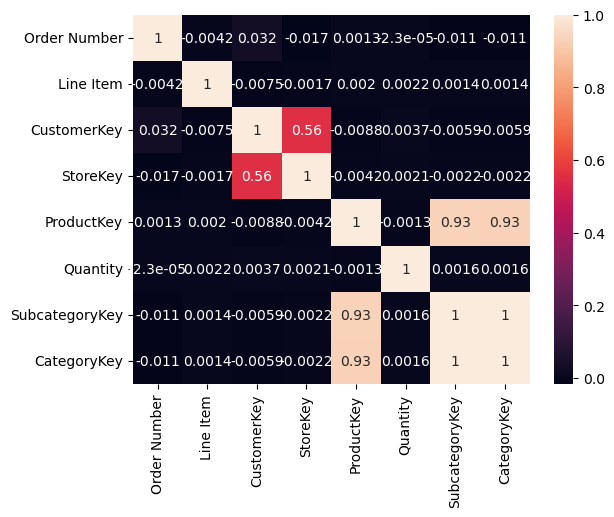

In [32]:
sns.heatmap(mydata.select_dtypes(include = 'number').corr(method = 'pearson') , annot  = True)

In [ ]:
mydata['Unit Cost USD'] = mydata['Unit Cost USD'].str.replace('$' , '')
mydata['Unit Price USD'] = mydata['Unit Price USD'].str.replace('$' , '')

C:\Users\user\AppData\Local\Temp\ipykernel_10324\1172703569.py:1: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  mydata['Unit Cost USD'] = mydata['Unit Cost USD'].str.replace('$' , '')
C:\Users\user\AppData\Local\Temp\ipykernel_10324\1172703569.py:2: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  mydata['Unit Price USD'] = mydata['Unit Price USD'].str.replace('$' , '')


In [40]:
mydata['Unit Cost USD'] = mydata['Unit Cost USD'].str.replace(',' , '')
mydata['Unit Price USD'] = mydata['Unit Price USD'].str.replace(',' , '')

In [41]:
mydata['Unit Cost USD'] = pd.to_numeric(mydata['Unit Cost USD'])
mydata['Unit Price USD'] = pd.to_numeric(mydata['Unit Price USD'])

In [42]:
mydata.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,31.27,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,141.47,427.00,402,Digital SLR Cameras,4,Cameras and camcorders
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,220.64,665.94,803,Microwaves,8,Home Appliances
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,148.08,322.00,402,Digital SLR Cameras,4,Cameras and camcorders
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,166.20,326.00,301,Laptops,3,Computers


<AxesSubplot:>

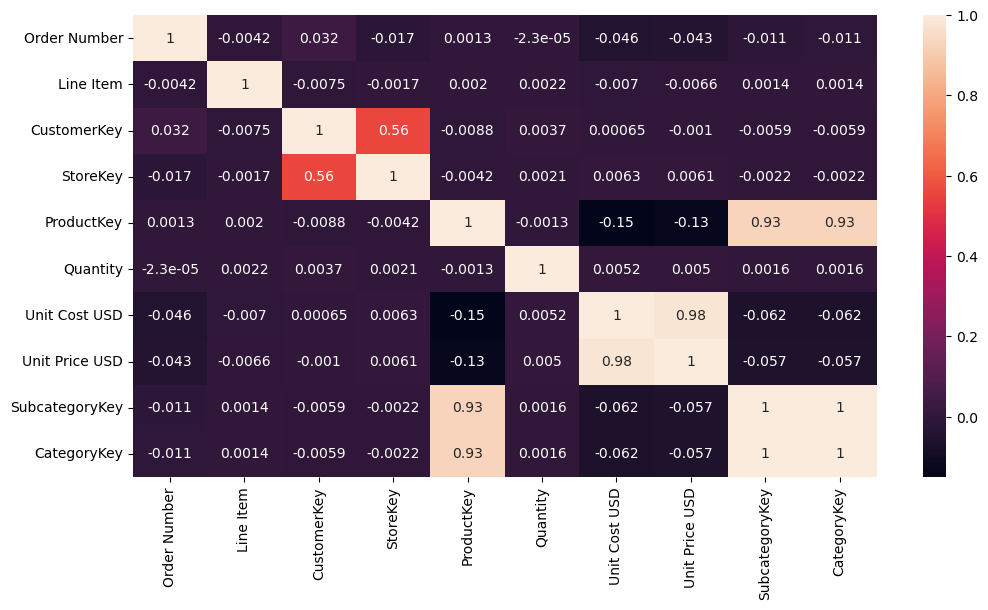

In [44]:
plt.figure(figsize = (12,6))
sns.heatmap(mydata.select_dtypes(include = 'number').corr(method = 'pearson') , annot  = True)

In [45]:
data2 = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Stores.csv")
data2.head()

,StoreKey,Country,State
0,1,Australia,Australian Capital Territory
1,2,Australia,Northern Territory
2,3,Australia,South Australia
3,4,Australia,Tasmania
4,5,Australia,Victoria


In [47]:
full_data = mydata.merge(data2 , on = 'StoreKey' , how = 'left')

In [50]:
full_data.duplicated().sum()

0

In [57]:
full_data['Delivery Date'] = full_data['Delivery Date'].fillna(method = 'bfill')
full_data['Order Date'] = full_data['Order Date'].fillna(method = 'bfill')

In [61]:
full_data.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category,Country,State
0,366000,1,1/1/2016,1/13/2016,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,31.27,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders,Canada,Nunavut
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,141.47,427.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,220.64,665.94,803,Microwaves,8,Home Appliances,Online,Online
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,148.08,322.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,166.20,326.00,301,Laptops,3,Computers,Online,Online


# $\textbf{EDA}$

In [66]:
full_data['Product Name'].value_counts().head(10)

Adventure Works Desktop PC2.30 MD230 Black    162
WWI Desktop PC1.60 E1600 Black                158
Adventure Works Desktop PC2.30 MD230 White    158
WWI Desktop PC1.80 E1800 White                158
WWI Desktop PC1.80 E1801 Black                157
WWI Desktop PC1.60 E1600 Silver               156
Adventure Works Desktop PC1.80 ED180 White    156
WWI Desktop PC1.80 E1800 Silver               156
Adventure Works Desktop PC1.60 ED160 Black    155
WWI Desktop PC2.33 X2330 Black                154
Name: Product Name, dtype: int64

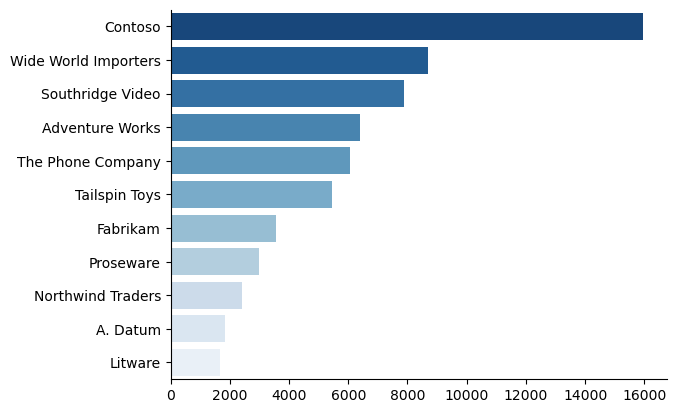

In [76]:
grp1 = full_data['Brand'].value_counts()
sns.barplot( x = grp1.values , y = grp1.index , palette = 'Blues_r')
sns.despine()

In [77]:
full_data['TotalPriceUSD'] = full_data['Unit Price USD'] * full_data['Quantity']
full_data['TotalCostUSD'] = full_data['Unit Cost USD'] * full_data['Quantity']
full_data['RevenueUSD'] = full_data['TotalPriceUSD'] - full_data['TotalCostUSD']

In [116]:
full_data.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,...,Subcategory,CategoryKey,Category,Country,State,TotalPriceUSD,TotalCostUSD,RevenueUSD,Month,Year
0,366000,1,2016-01-01,2016-01-13,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,...,Cameras & Camcorders Accessories,4,Cameras and camcorders,Canada,Nunavut,68.00,31.27,36.73,1,2016
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,...,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,854.00,282.94,571.06,1,2016
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,...,Microwaves,8,Home Appliances,Online,Online,665.94,220.64,445.30,1,2016
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,...,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,2254.00,1036.56,1217.44,1,2016
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,...,Laptops,3,Computers,Online,Online,326.00,166.20,159.80,1,2016


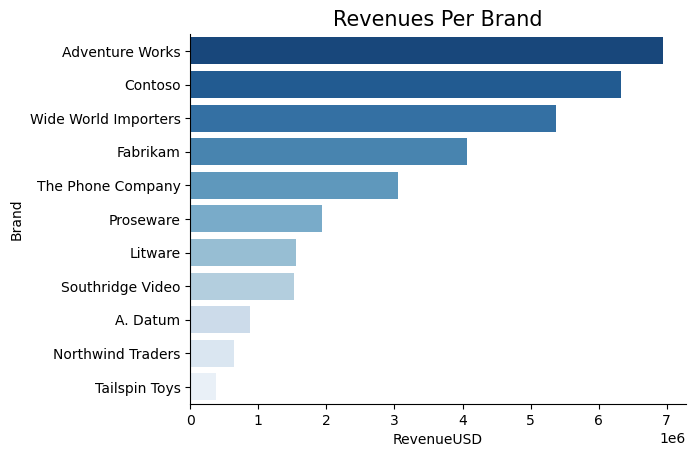

In [85]:
grp2 = full_data.groupby('Brand')['RevenueUSD'].sum().sort_values(ascending = False).reset_index()
sns.barplot( data = grp2 , x = 'RevenueUSD' , y = 'Brand' , palette = 'Blues_r')
plt.title('Revenues Per Brand' , fontsize =15)
sns.despine()

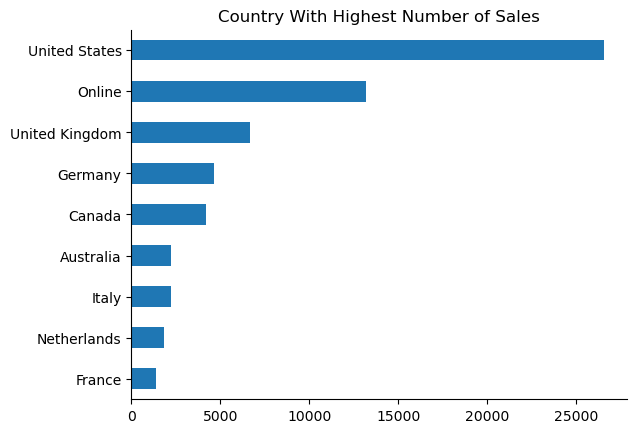

In [90]:
full_data['Country'].value_counts().sort_values(ascending = True).plot(kind = 'barh' , title = 'Country With Highest Number of Sales')
sns.despine()

In [92]:
full_data['Order Date'] = pd.to_datetime(full_data['Order Date'])
full_data['Delivery Date'] = pd.to_datetime(full_data['Delivery Date'])

In [93]:
full_data['Month'] = full_data['Delivery Date'].dt.month
full_data['Year'] = full_data['Delivery Date'].dt.year

In [100]:
time_data = full_data.copy()

In [102]:

time_data = time_data.sort_values(by ='Delivery Date' , ascending = True)
time_data = time_data.set_index('Delivery Date')

In [115]:
time_data.head(2)

,Order Number,Line Item,Order Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,...,Subcategory,CategoryKey,Category,Country,State,TotalPriceUSD,TotalCostUSD,RevenueUSD,Month,Year
Delivery Date,,,,,,,,,,,,,,,,,,,,,
2016-01-06,366012,2,2016-01-01,1977527,65,1594,4,USD,SV DVD 38 DVD Storage Binder E25 Red,Southridge Video,...,Movie DVD,6,"Music, Movies and Audio Books",United States,West Virginia,39.96,20.36,19.6,1,2016
2016-01-06,366014,2,2016-01-01,738549,0,1700,2,EUR,SV Hand Games women M40 Red,Southridge Video,...,Boxed Games,7,Games and Toys,Online,Online,17.76,8.16,9.6,1,2016


<AxesSubplot:xlabel='Delivery Date'>

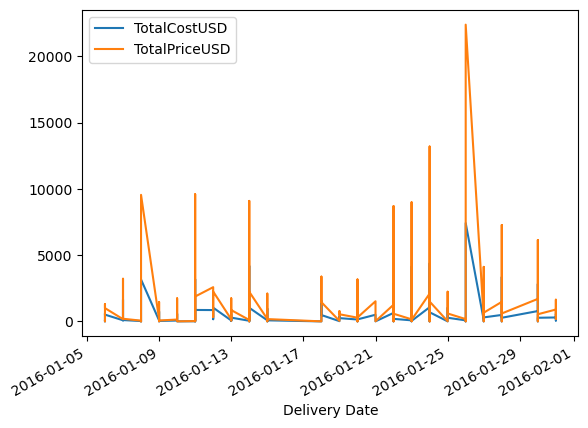

In [110]:
time_data.loc['2016-01' , ['TotalCostUSD' , 'TotalPriceUSD']].plot(kind = 'line')

<AxesSubplot:title={'center':'Avg Revenue By Country'}, ylabel='Country'>

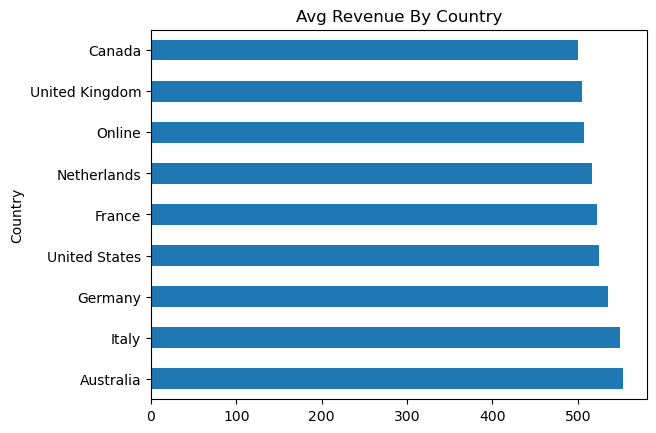

In [114]:
full_data.groupby('Country')['RevenueUSD'].mean().sort_values(ascending = False).plot(kind = 'barh' , title = 'Avg Revenue By Country')

In [124]:
grp3 = full_data.groupby('Brand')['Quantity'].sum().sort_values(ascending = False).reset_index()
grp3['Percent_goods'] = round((grp3['Quantity']/grp3['Quantity'].sum())*100 , 2)
grp3

,Brand,Quantity,Percent_goods
0,Contoso,49827,25.20
1,Wide World Importers,27413,13.86
2,Southridge Video,24814,12.55
3,Adventure Works,20099,10.16
4,The Phone Company,18764,9.49
5,Tailspin Toys,17455,8.83
6,Fabrikam,11384,5.76
7,Proseware,9427,4.77
8,Northwind Traders,7610,3.85
9,A. Datum,5655,2.86


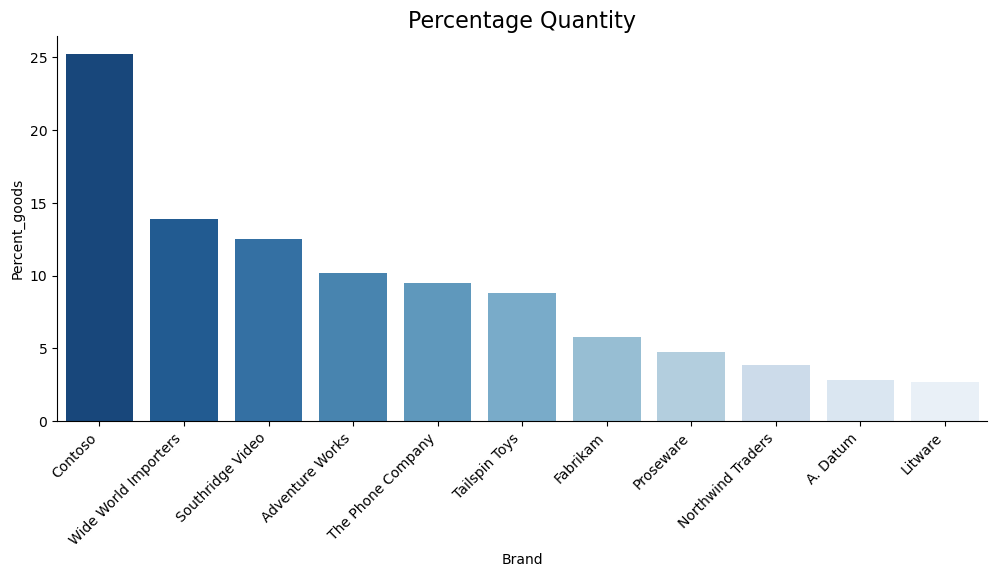

In [130]:
plt.figure(figsize = (12,5))
sns.barplot(data = grp3 , x = 'Brand' , y = 'Percent_goods' , palette = 'Blues_r')
plt.title('Percentage Quantity' , fontsize = 16)
plt.xticks(rotation = 45 , ha = 'right')
sns.despine()
plt.show()

# Linear Regression

In [157]:
mydata = pd.read_csv('synthetic_flight_passenger_data.csv')
mydata.head()

,Passenger_ID,Flight_ID,Airline,Departure_Airport,Arrival_Airport,Departure_Time,Flight_Duration_Minutes,Flight_Status,Distance_Miles,Price_USD,...,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
0,P1,F68,Southwest,JFK,ATL,2024-03-27 06:22:06,161,On-time,803,148.42,...,2,Platinum,Online,8.801356,0.0,91,1,1,Window,102
1,P2,F1687,Southwest,JFK,DFW,2024-12-28 09:18:06,130,On-time,1605,228.57,...,1,Gold,Airport Kiosk,9.094380,2.0,45,0,0,Middle,51
2,P3,F1745,United,ORD,ORD,2024-05-23 23:28:20,169,On-time,908,232.45,...,0,Silver,Airport Kiosk,8.015235,0.0,63,0,0,Middle,92
3,P4,F1514,Delta,SEA,ORD,2023-10-31 08:09:27,227,On-time,63,526.43,...,0,Platinum,Online,7.544133,9.0,57,0,1,Window,14
4,P5,F1753,Southwest,LAX,JFK,2025-01-17 22:21:13,150,On-time,628,324.14,...,2,Silver,Desk,7.133140,3.0,58,0,0,Middle,106


In [161]:
mydata.iloc[: , 10:18]

,Age,Gender,Income_Level,Travel_Purpose,Seat_Class,Bags_Checked,Frequent_Flyer_Status,Check_in_Method
0,47,Male,Medium,Emergency,Business,2,Platinum,Online
1,30,Female,Low,Family,Business,1,Gold,Airport Kiosk
2,46,Male,Low,Business,Economy,0,Silver,Airport Kiosk
3,75,Female,Medium,Leisure,Business,0,Platinum,Online
4,23,Male,High,Family,Economy,2,Silver,Desk
...,...,...,...,...,...,...,...,...
9995,34,Male,Low,Leisure,Economy,1,NaN,Desk
9996,49,Male,Medium,Leisure,Economy,3,NaN,Airport Kiosk
9997,58,Male,High,Emergency,Economy,3,NaN,Desk
9998,49,Male,Low,Leisure,Economy,0,Gold,Online


In [160]:
mydata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Passenger_ID               10000 non-null  object 
 1   Flight_ID                  10000 non-null  object 
 2   Airline                    10000 non-null  object 
 3   Departure_Airport          10000 non-null  object 
 4   Arrival_Airport            10000 non-null  object 
 5   Departure_Time             10000 non-null  object 
 6   Flight_Duration_Minutes    10000 non-null  int64  
 7   Flight_Status              10000 non-null  object 
 8   Distance_Miles             10000 non-null  int64  
 9   Price_USD                  10000 non-null  float64
 10  Age                        10000 non-null  int64  
 11  Gender                     10000 non-null  object 
 12  Income_Level               10000 non-null  object 
 13  Travel_Purpose             10000 non-null  obje

In [177]:
mydata.select_dtypes(include = 'number').corr()

,Flight_Duration_Minutes,Distance_Miles,Price_USD,Age,Bags_Checked,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Booking_Lead_Time
Flight_Duration_Minutes,1.000000,-0.007827,-0.002824,-0.008321,0.005906,-0.007804,0.003431,0.006577,0.000762,0.005269,-0.006087
Distance_Miles,-0.007827,1.000000,-0.003111,0.010714,0.001494,-0.007335,0.001299,-0.002091,-0.009191,0.011934,0.000104
Price_USD,-0.002824,-0.003111,1.000000,-0.013431,0.005118,0.015240,-0.007709,0.002751,0.012810,-0.005732,0.004999
Age,-0.008321,0.010714,-0.013431,1.000000,0.016208,0.001708,-0.002126,0.011976,-0.013931,0.007324,0.009780
Bags_Checked,0.005906,0.001494,0.005118,0.016208,1.000000,-0.005483,-0.009683,-0.011523,-0.002069,-0.017095,-0.009769
Flight_Satisfaction_Score,-0.007804,-0.007335,0.015240,0.001708,-0.005483,1.000000,-0.228451,-0.001854,-0.000578,-0.011789,0.419285
Delay_Minutes,0.003431,0.001299,-0.007709,-0.002126,-0.009683,-0.228451,1.000000,0.014904,-0.005512,0.011928,0.007749
Booking_Days_In_Advance,0.006577,-0.002091,0.002751,0.011976,-0.011523,-0.001854,0.014904,1.000000,-0.008832,0.002411,0.003242
No_Show,0.000762,-0.009191,0.012810,-0.013931,-0.002069,-0.000578,-0.005512,-0.008832,1.000000,0.012684,0.006039
Weather_Impact,0.005269,0.011934,-0.005732,0.007324,-0.017095,-0.011789,0.011928,0.002411,0.012684,1.000000,-0.009713


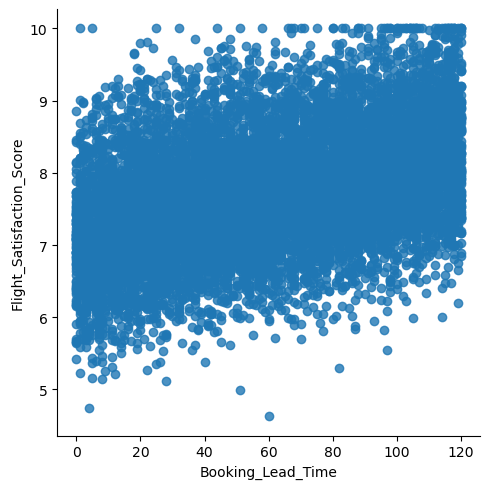

In [178]:
sns.lmplot(data = mydata , x = 'Booking_Lead_Time' , y = 'Flight_Satisfaction_Score')

In [194]:
data = pd.read_csv("C:/Users/user/Desktop/Machine Learning Full/Linear Regression/1000_Companies.csv")
data.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [184]:
data.select_dtypes(include = 'number').corr()

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.582434,0.978407,0.945245
Administration,0.582434,1.000000,0.520465,0.741560
Marketing Spend,0.978407,0.520465,1.000000,0.917270
Profit,0.945245,0.741560,0.917270,1.000000


In [185]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        1000 non-null   float64
 1   Administration   1000 non-null   float64
 2   Marketing Spend  1000 non-null   float64
 3   State            1000 non-null   object 
 4   Profit           1000 non-null   float64
dtypes: float64(4), object(1)
memory usage: 39.2+ KB


c:\Users\user\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='Profit'>

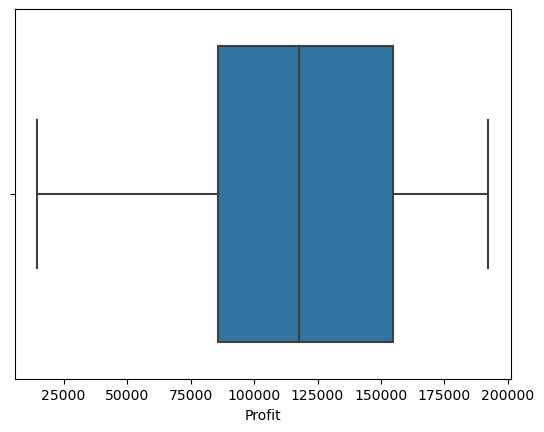

In [192]:
sns.boxplot(data['Profit'])

In [200]:
data['Profit'].describe()

count      1000.000000
mean     118680.399050
std       39728.667112
min       14681.400000
25%       85943.198543
50%      117641.466300
75%      154799.937300
max      192261.830000
Name: Profit, dtype: float64

In [198]:
IQR3 = 155577.107425 - 85943.198543
outliers   = 3*IQR3
outliers 

208901.72664599997

In [199]:
data[data['Profit'] > outliers ] = data['Profit'].mean()

In [208]:
X = data[['Marketing Spend']]
y = data[['Profit']]

In [209]:
from sklearn.model_selection import train_test_split

In [210]:
X_train , X_test , y_train , y_test = train_test_split(X , y  , test_size = .2 , random_state = 42)

In [211]:
from sklearn.linear_model import LinearRegression

In [212]:
model = LinearRegression()
model.fit(X_train , y_train)

LinearRegression()

In [213]:
model.score(X_test , y_test)

0.9719565995571418

In [214]:
y_pred = model.predict(X_test)

In [221]:
from sklearn.metrics import r2_score
r2_score(y_test , y_pred)

0.9719565995571418

In [223]:
import joblib
joblib.dump(model , 'model.pkl')

['model.pkl']

In [224]:
data['Marketing Spend'].describe()

count      1000.000000
mean     225759.419603
std       91720.687513
min           0.000000
25%      149567.800875
50%      223738.368250
75%      308189.808525
max      471784.100000
Name: Marketing Spend, dtype: float64

# Multiple Linear Regression

In [228]:
data.select_dtypes(include = 'number').corr(method = 'pearson')

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.749865,0.973164,0.997702
Administration,0.749865,1.000000,0.693611,0.745075
Marketing Spend,0.973164,0.693611,1.000000,0.978454
Profit,0.997702,0.745075,0.978454,1.000000


<AxesSubplot:>

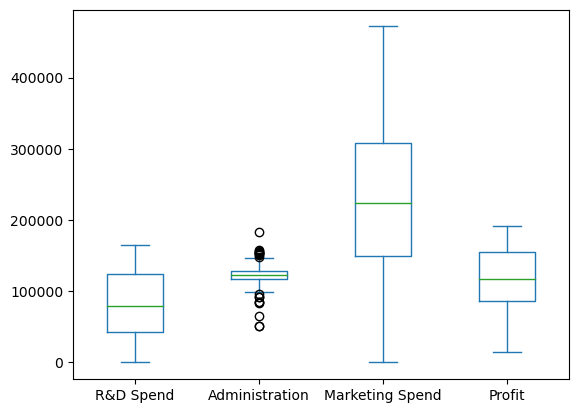

In [231]:
data.select_dtypes(include = 'number').plot(kind = 'box')

In [232]:
data.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')

In [235]:
X = data[['R&D Spend',  'Marketing Spend']]
y = data['Profit']

In [236]:
from sklearn.model_selection import train_test_split

In [237]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = .2, random_state = 42)

In [238]:
from sklearn.linear_model import LinearRegression

In [239]:
model1 = LinearRegression()
model1.fit(X_train , y_train)

LinearRegression()

In [240]:
y_pred = model1.predict(X_test)

In [241]:
from sklearn.metrics import r2_score 

In [242]:
r2_score(y_test , y_pred)

0.997771216825461

In [243]:
import joblib 
joblib.dump(model1 , 'multilinear.pkl')

['multilinear.pkl']

In [244]:
X.columns

Index(['R&D Spend', 'Marketing Spend'], dtype='object')

# Data Exploration

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
new_data = pd.read_csv('synthetic_flight_passenger_data.csv')
new_data.head()

,Passenger_ID,Flight_ID,Airline,Departure_Airport,Arrival_Airport,Departure_Time,Flight_Duration_Minutes,Flight_Status,Distance_Miles,Price_USD,...,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
0,P1,F68,Southwest,JFK,ATL,2024-03-27 06:22:06,161,On-time,803,148.42,...,2,Platinum,Online,8.801356,0.0,91,1,1,Window,102
1,P2,F1687,Southwest,JFK,DFW,2024-12-28 09:18:06,130,On-time,1605,228.57,...,1,Gold,Airport Kiosk,9.094380,2.0,45,0,0,Middle,51
2,P3,F1745,United,ORD,ORD,2024-05-23 23:28:20,169,On-time,908,232.45,...,0,Silver,Airport Kiosk,8.015235,0.0,63,0,0,Middle,92
3,P4,F1514,Delta,SEA,ORD,2023-10-31 08:09:27,227,On-time,63,526.43,...,0,Platinum,Online,7.544133,9.0,57,0,1,Window,14
4,P5,F1753,Southwest,LAX,JFK,2025-01-17 22:21:13,150,On-time,628,324.14,...,2,Silver,Desk,7.133140,3.0,58,0,0,Middle,106


In [5]:
new_data.iloc[:,10:].head()

,Age,Gender,Income_Level,Travel_Purpose,Seat_Class,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
0,47,Male,Medium,Emergency,Business,2,Platinum,Online,8.801356,0.0,91,1,1,Window,102
1,30,Female,Low,Family,Business,1,Gold,Airport Kiosk,9.094380,2.0,45,0,0,Middle,51
2,46,Male,Low,Business,Economy,0,Silver,Airport Kiosk,8.015235,0.0,63,0,0,Middle,92
3,75,Female,Medium,Leisure,Business,0,Platinum,Online,7.544133,9.0,57,0,1,Window,14
4,23,Male,High,Family,Economy,2,Silver,Desk,7.133140,3.0,58,0,0,Middle,106


In [6]:
new_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Passenger_ID               10000 non-null  object 
 1   Flight_ID                  10000 non-null  object 
 2   Airline                    10000 non-null  object 
 3   Departure_Airport          10000 non-null  object 
 4   Arrival_Airport            10000 non-null  object 
 5   Departure_Time             10000 non-null  object 
 6   Flight_Duration_Minutes    10000 non-null  int64  
 7   Flight_Status              10000 non-null  object 
 8   Distance_Miles             10000 non-null  int64  
 9   Price_USD                  10000 non-null  float64
 10  Age                        10000 non-null  int64  
 11  Gender                     10000 non-null  object 
 12  Income_Level               10000 non-null  object 
 13  Travel_Purpose             10000 non-null  obje

In [7]:
new_data['Frequent_Flyer_Status'].unique()

array(['Platinum', 'Gold', 'Silver', nan], dtype=object)

In [8]:
new_data.describe()

,Flight_Duration_Minutes,Distance_Miles,Price_USD,Age,Bags_Checked,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Booking_Lead_Time
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,180.156100,1199.178500,349.008031,48.590500,0.993200,7.722048,9.975000,59.936800,0.051100,0.150700,59.820300
std,60.304822,302.818297,99.824544,18.019858,0.993404,0.847221,9.905311,34.695827,0.220213,0.357774,35.029669
min,-78.000000,-10.000000,-40.620000,18.000000,0.000000,4.630153,0.000000,0.000000,0.000000,0.000000,0.000000
25%,140.000000,998.000000,282.615000,33.000000,0.000000,7.134095,3.000000,30.000000,0.000000,0.000000,29.000000
50%,180.000000,1194.500000,349.840000,49.000000,1.000000,7.688090,7.000000,61.000000,0.000000,0.000000,59.000000
75%,221.000000,1400.000000,415.270000,64.000000,2.000000,8.291409,14.000000,90.000000,0.000000,0.000000,90.000000
max,442.000000,2558.000000,830.440000,79.000000,6.000000,10.000000,87.000000,119.000000,1.000000,1.000000,120.000000


In [10]:
new_data.select_dtypes(include='number').corr()

,Flight_Duration_Minutes,Distance_Miles,Price_USD,Age,Bags_Checked,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Booking_Lead_Time
Flight_Duration_Minutes,1.000000,-0.007827,-0.002824,-0.008321,0.005906,-0.007804,0.003431,0.006577,0.000762,0.005269,-0.006087
Distance_Miles,-0.007827,1.000000,-0.003111,0.010714,0.001494,-0.007335,0.001299,-0.002091,-0.009191,0.011934,0.000104
Price_USD,-0.002824,-0.003111,1.000000,-0.013431,0.005118,0.015240,-0.007709,0.002751,0.012810,-0.005732,0.004999
Age,-0.008321,0.010714,-0.013431,1.000000,0.016208,0.001708,-0.002126,0.011976,-0.013931,0.007324,0.009780
Bags_Checked,0.005906,0.001494,0.005118,0.016208,1.000000,-0.005483,-0.009683,-0.011523,-0.002069,-0.017095,-0.009769
Flight_Satisfaction_Score,-0.007804,-0.007335,0.015240,0.001708,-0.005483,1.000000,-0.228451,-0.001854,-0.000578,-0.011789,0.419285
Delay_Minutes,0.003431,0.001299,-0.007709,-0.002126,-0.009683,-0.228451,1.000000,0.014904,-0.005512,0.011928,0.007749
Booking_Days_In_Advance,0.006577,-0.002091,0.002751,0.011976,-0.011523,-0.001854,0.014904,1.000000,-0.008832,0.002411,0.003242
No_Show,0.000762,-0.009191,0.012810,-0.013931,-0.002069,-0.000578,-0.005512,-0.008832,1.000000,0.012684,0.006039
Weather_Impact,0.005269,0.011934,-0.005732,0.007324,-0.017095,-0.011789,0.011928,0.002411,0.012684,1.000000,-0.009713


# Insights

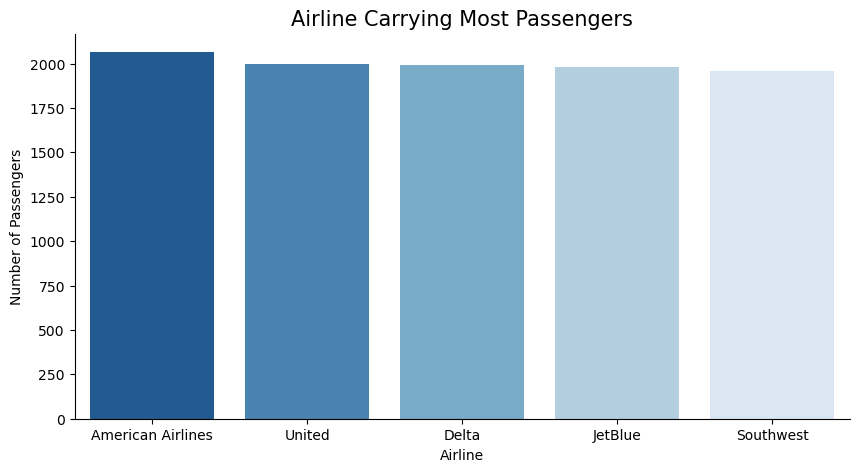

In [18]:
plt.figure(figsize=(10 , 5))
grp = new_data.groupby('Airline')['Passenger_ID'].count().sort_values(ascending = False).reset_index()
sns.barplot(data = grp , x = 'Airline' , y = 'Passenger_ID' , palette = 'Blues_r')
plt.title('Airline Carrying Most Passengers' , fontsize =15)
sns.despine()
plt.ylabel('Number of Passengers')
plt.show()

### Busy Airports

Text(0, 0.5, 'Count Of Flights')

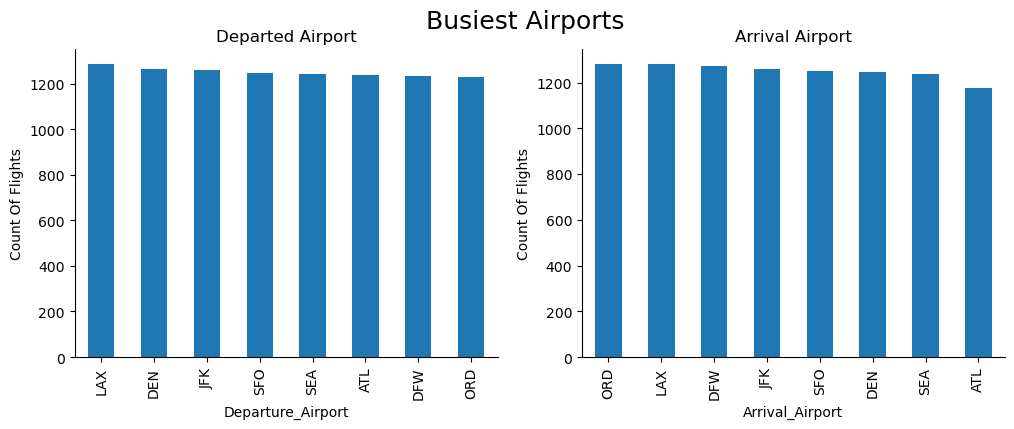

In [30]:
fig , (ax1 , ax2) = plt.subplots(1,2 , figsize = (12,4))

sns.despine()
new_data.groupby('Departure_Airport').size().sort_values(ascending = False).plot(kind = 'bar' , title = 'Departed Airport' , ax = ax1)

new_data.groupby('Arrival_Airport').size().sort_values(ascending = False).plot(kind = 'bar' , title = 'Arrival Airport' , ax = ax2)
plt.suptitle('Busiest Airports' , fontsize = 18)
ax1.set_ylabel('Count Of Flights')
ax2.set_ylabel('Count Of Flights')


In [36]:
new_data = new_data.sort_values('Departure_Time')

In [37]:
new_data['Departure_Time'] = pd.to_datetime(new_data['Departure_Time'])

In [38]:
time_data = new_data.copy()

In [39]:
time_data.set_index('Departure_Time' , inplace = True)

In [40]:
time_data.head()

,Passenger_ID,Flight_ID,Airline,Departure_Airport,Arrival_Airport,Flight_Duration_Minutes,Flight_Status,Distance_Miles,Price_USD,Age,...,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
Departure_Time,,,,,,,,,,,,,,,,,,,,,
2023-04-23 07:18:08,P1345,F433,American Airlines,SFO,ATL,137,On-time,1140,309.20,62,...,1,Platinum,Mobile App,8.131924,2.0,118,0,0,Window,107
2023-04-23 08:09:35,P2324,F1677,JetBlue,JFK,DFW,159,On-time,1482,258.86,68,...,1,NaN,Desk,7.946594,4.0,86,0,0,Aisle,57
2023-04-23 09:13:21,P938,F697,United,DFW,SFO,219,On-time,1605,555.76,77,...,0,NaN,Desk,7.229571,3.0,59,0,0,Middle,76
2023-04-23 09:20:21,P5515,F150,United,DFW,ORD,70,On-time,1284,255.00,32,...,1,Platinum,Desk,8.485618,1.0,17,0,0,Middle,37
2023-04-23 09:52:35,P4702,F785,Southwest,JFK,DFW,238,On-time,787,495.93,41,...,0,Silver,Online,8.678691,3.0,4,0,1,Aisle,61


In [45]:
time_data['Hour'] =  time_data.index.hour
time_data['Day_of_week'] =  time_data.index.dayofweek
time_data['Month'] =  time_data.index.month
time_data['Year'] =  time_data.index.year

Text(0, 0.5, 'Count')

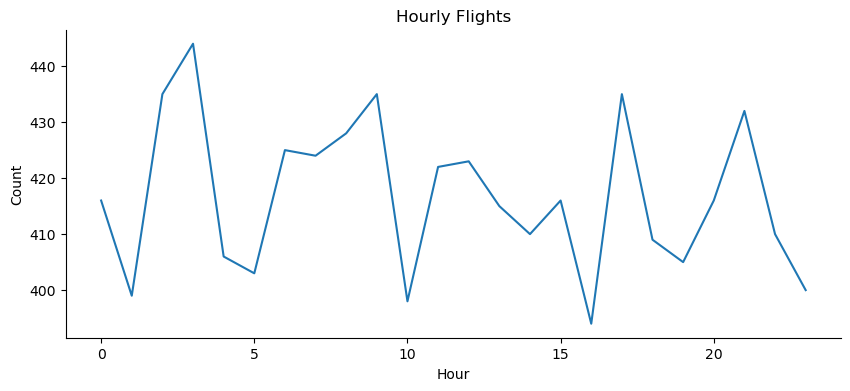

In [60]:
time_data.groupby('Hour')['Hour'].count().plot(kind = 'line' , figsize = (10 , 4) , title = 'Hourly Flights')
sns.despine()
plt.ylabel('Count')

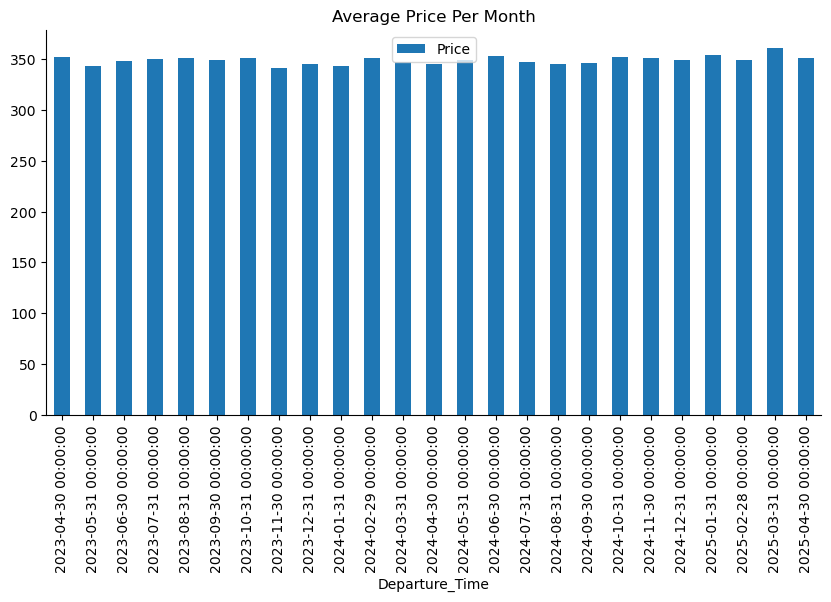

In [134]:
new_data.set_index('Departure_Time').resample('M').agg(Price = ('Price_USD' , 'mean')).plot(kind = 'bar' , 
                                                                                            title = 'Average Price Per Month' ,figsize = (10 , 5))




sns.despine()

In [70]:
new_data.iloc[: , 10:]

,Age,Gender,Income_Level,Travel_Purpose,Seat_Class,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
1344,62,Female,Low,Business,Premium Economy,1,Platinum,Mobile App,8.131924,2.0,118,0,0,Window,107
2323,68,Male,High,Leisure,Economy,1,NaN,Desk,7.946594,4.0,86,0,0,Aisle,57
937,77,Female,Medium,Leisure,Economy,0,NaN,Desk,7.229571,3.0,59,0,0,Middle,76
5514,32,Female,Low,Emergency,Premium Economy,1,Platinum,Desk,8.485618,1.0,17,0,0,Middle,37
4701,41,Female,Low,Emergency,Business,0,Silver,Online,8.678691,3.0,4,0,1,Aisle,61
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,79,Male,Medium,Business,Business,0,Gold,Mobile App,7.631820,5.0,53,0,0,Middle,60
9171,24,Male,Medium,Family,Economy,2,Silver,Online,5.951689,36.0,18,0,1,Aisle,60
1085,39,Female,Medium,Family,Economy,2,NaN,Mobile App,7.503521,3.0,116,0,0,Window,76
605,20,Male,Medium,Business,Premium Economy,1,Platinum,Mobile App,8.612839,1.0,116,0,0,Aisle,68


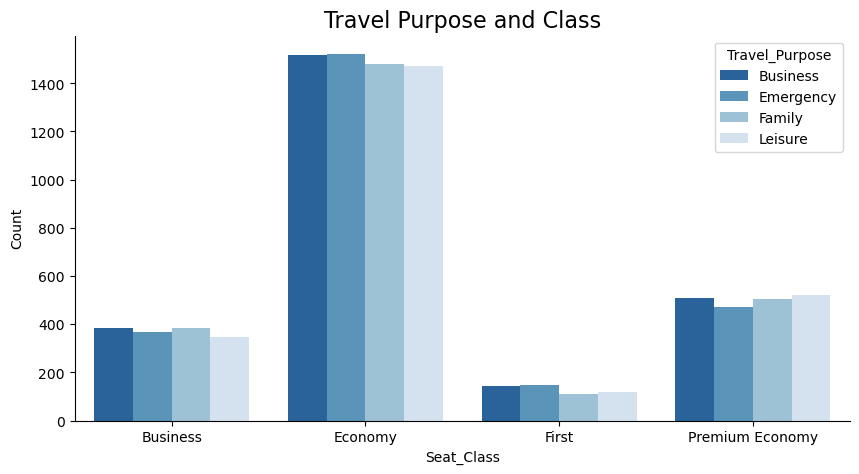

In [84]:
grp1 = new_data.groupby(['Travel_Purpose' , 'Seat_Class']).size().reset_index(name = 'Count')
plt.figure(figsize = (10 , 5))
sns.barplot(data = grp1 , x ='Seat_Class' , y = 'Count' , hue = 'Travel_Purpose' , palette = 'Blues_r')
plt.title('Travel Purpose and Class' , fontsize = 16)
sns.despine()

Text(0.5, 1.0, 'Income Level and Class')

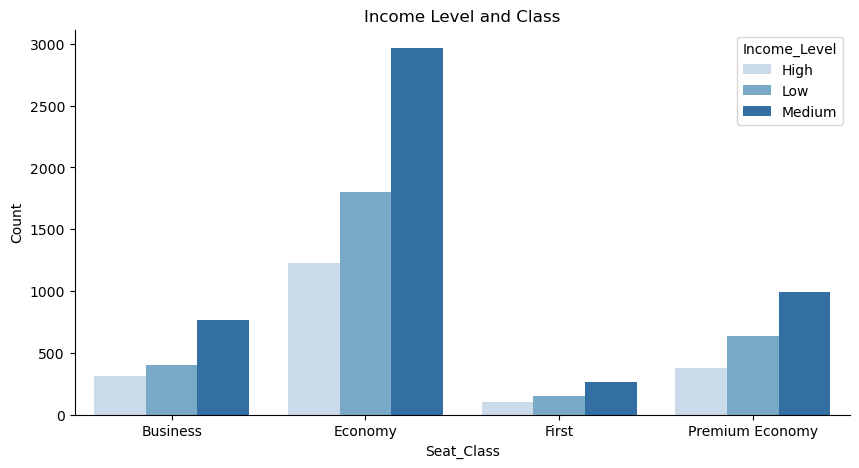

In [89]:
grp2 = new_data.groupby(['Income_Level' , 'Seat_Class']).size().reset_index(name = 'Count')
plt.figure(figsize = (10 , 5))
sns.barplot(data = grp2 , x = 'Seat_Class'   ,y = 'Count' , hue = 'Income_Level'  , palette = 'Blues')
sns.despine()
plt.title('Income Level and Class')


In [95]:
import plotly.express as px

In [105]:
grp3 = new_data['Frequent_Flyer_Status'].value_counts().reset_index()
px.pie(data_frame = grp3 , labels = 'index' , values = 'Frequent_Flyer_Status')

In [102]:
grp3

,index,Frequent_Flyer_Status
0,Silver,2550
1,Gold,1488
2,Platinum,1014


In [106]:
new_data['Check_in_Method'].value_counts()

Desk             2542
Online           2529
Mobile App       2469
Airport Kiosk    2460
Name: Check_in_Method, dtype: int64

In [112]:
grp4 = new_data.groupby('Airline')[['Flight_Satisfaction_Score' ,'Delay_Minutes' ]].sum().reset_index()

grp4['Perc_Satis_Score'] = round((grp4['Flight_Satisfaction_Score']/grp4['Flight_Satisfaction_Score'].sum())*100 ,2)
grp4['Perc_Delay_Minutes'] = round((grp4['Delay_Minutes']/grp4['Delay_Minutes'].sum())*100 , 2)

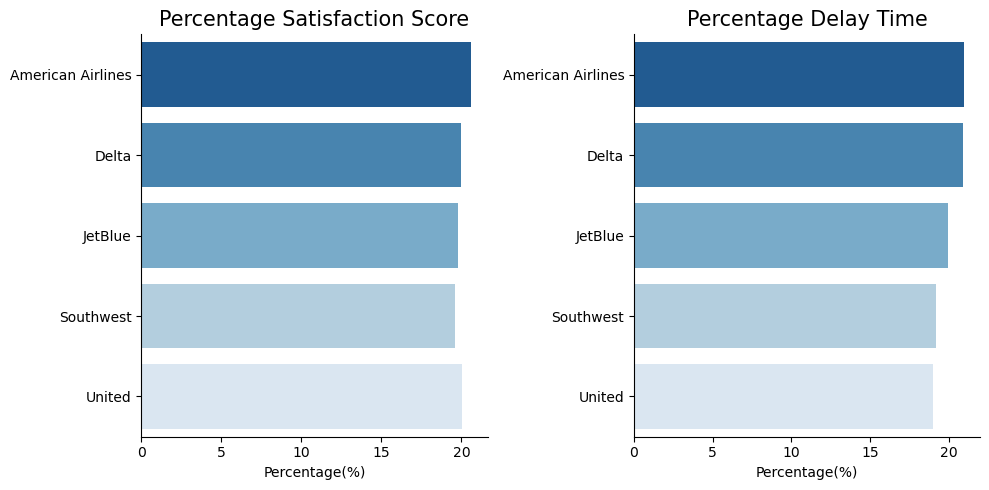

In [118]:
fig , (ax1 , ax2) = plt.subplots(1,2 , figsize = (10 , 5))
sns.despine()
sns.barplot(data = grp4 , y ='Airline' , x = 'Perc_Satis_Score'  ,ax = ax1 , palette = 'Blues_r')
ax1.set_title('Percentage Satisfaction Score' , fontsize = 15)
ax1.set_ylabel('')
ax1.set_xlabel('Percentage(%)')

sns.barplot(data = grp4 , y ='Airline' , x = 'Perc_Delay_Minutes'  ,ax = ax2 , palette = 'Blues_r')
ax2.set_title('Percentage Delay Time' , fontsize = 15)
ax2.set_ylabel('')
ax2.set_xlabel('Percentage(%)')
plt.tight_layout()

<AxesSubplot:ylabel='Flight_Status'>

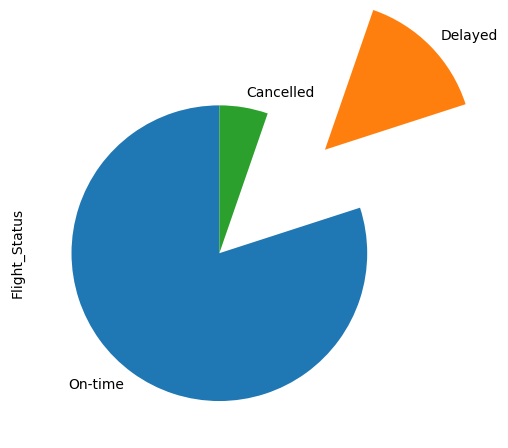

In [126]:
new_data['Flight_Status'].value_counts().plot(kind = 'pie' , startangle = 90 , explode = (0,1,0))

In [127]:
new_data

,Passenger_ID,Flight_ID,Airline,Departure_Airport,Arrival_Airport,Departure_Time,Flight_Duration_Minutes,Flight_Status,Distance_Miles,Price_USD,...,Bags_Checked,Frequent_Flyer_Status,Check_in_Method,Flight_Satisfaction_Score,Delay_Minutes,Booking_Days_In_Advance,No_Show,Weather_Impact,Seat_Selected,Booking_Lead_Time
1344,P1345,F433,American Airlines,SFO,ATL,2023-04-23 07:18:08,137,On-time,1140,309.20,...,1,Platinum,Mobile App,8.131924,2.0,118,0,0,Window,107
2323,P2324,F1677,JetBlue,JFK,DFW,2023-04-23 08:09:35,159,On-time,1482,258.86,...,1,NaN,Desk,7.946594,4.0,86,0,0,Aisle,57
937,P938,F697,United,DFW,SFO,2023-04-23 09:13:21,219,On-time,1605,555.76,...,0,NaN,Desk,7.229571,3.0,59,0,0,Middle,76
5514,P5515,F150,United,DFW,ORD,2023-04-23 09:20:21,70,On-time,1284,255.00,...,1,Platinum,Desk,8.485618,1.0,17,0,0,Middle,37
4701,P4702,F785,Southwest,JFK,DFW,2023-04-23 09:52:35,238,On-time,787,495.93,...,0,Silver,Online,8.678691,3.0,4,0,1,Aisle,61
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,P1595,F150,United,DFW,DEN,2025-04-22 01:47:05,187,On-time,876,221.57,...,0,Gold,Mobile App,7.631820,5.0,53,0,0,Middle,60
9171,P9172,F862,United,DEN,DFW,2025-04-22 06:05:22,226,On-time,944,289.72,...,2,Silver,Online,5.951689,36.0,18,0,1,Aisle,60
1085,P1086,F956,United,LAX,JFK,2025-04-22 08:49:36,197,On-time,920,248.08,...,2,NaN,Mobile App,7.503521,3.0,116,0,0,Window,76
605,P606,F1830,Delta,LAX,ATL,2025-04-22 09:22:10,169,On-time,1186,354.22,...,1,Platinum,Mobile App,8.612839,1.0,116,0,0,Aisle,68


In [ ]:
grp5 = new_data.groupby('Airline')['Passenger_ID'].count().sort_values(ascending = False).reset_index()

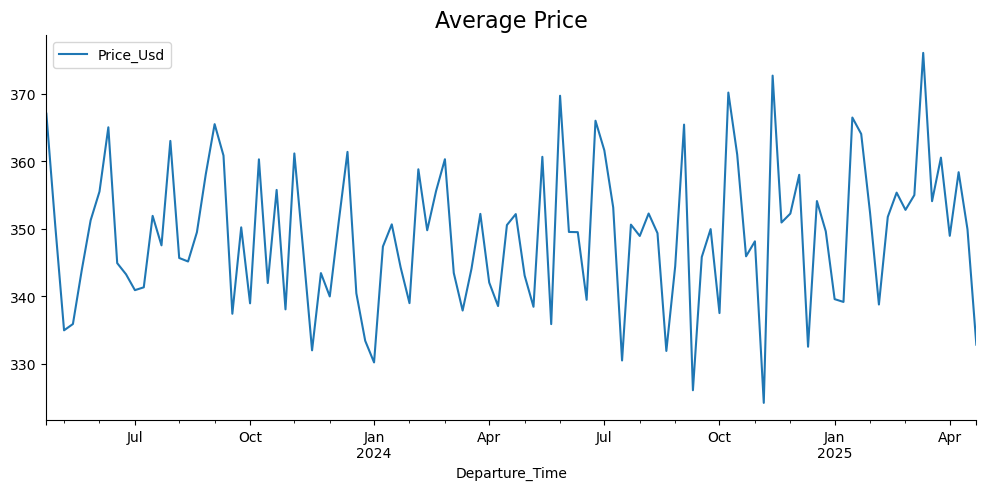

In [145]:
new_data.set_index('Departure_Time').resample('W').agg(Distance_Miles =('Distance_Miles' , 'sum'),
                                  Price_Usd = ('Price_USD' , 'mean')).plot(kind = 'line' , y = 'Price_Usd' , figsize = (12 , 5))
plt.title('Average Price' , fontsize = 16)
sns.despine()

In [148]:
time_series = new_data.set_index('Departure_Time').resample('W').agg(Distance_Miles =('Distance_Miles' , 'sum'),
                                                                     Price_Usd = ('Price_USD' , 'mean'))
time_series

,Distance_Miles,Price_Usd
Departure_Time,,
2023-04-23,13671,367.048333
2023-04-30,118833,350.551300
2023-05-07,114588,334.931979
2023-05-14,113016,335.864898
2023-05-21,111155,343.870753
...,...,...
2025-03-30,112466,360.530114
2025-04-06,123727,348.941869
2025-04-13,127893,358.371887


In [150]:
time_series1 = time_series.copy()

<AxesSubplot:xlabel='Departure_Time', ylabel='Price_Usd'>

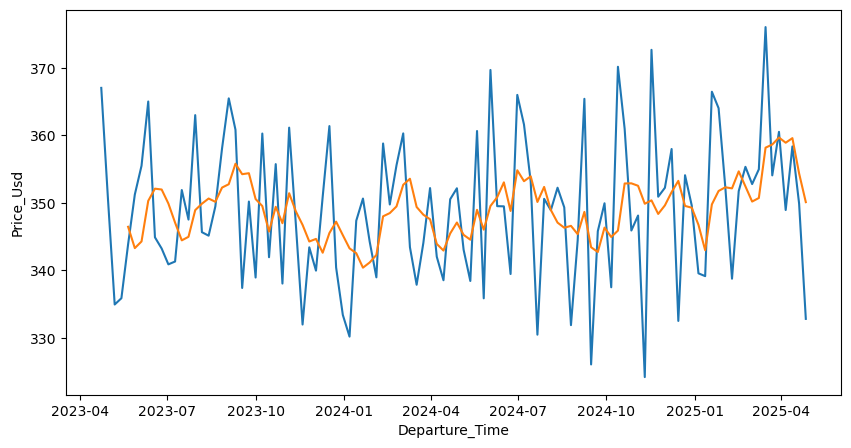

In [158]:
time_series1['P_moving_avg'] = time_series1['Price_Usd'].rolling(window=5 ).mean()
plt.figure(figsize = (10 , 5))
sns.lineplot(data = time_series1 , x = time_series1.index , y = 'Price_Usd')
sns.lineplot(data = time_series1 , x = time_series1.index , y = 'P_moving_avg')

<AxesSubplot:xlabel='Departure_Time', ylabel='Price_Usd'>

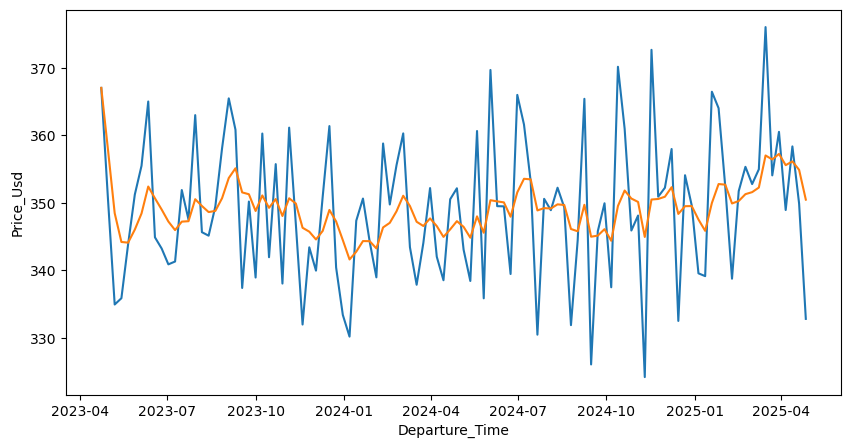

In [160]:
time_series1['exp_price'] = time_series1['Price_Usd'].ewm(alpha=0.2).mean() 

plt.figure(figsize = (10 , 5))
sns.lineplot(data = time_series1 , x = time_series1.index , y = 'Price_Usd')
sns.lineplot(data = time_series1 , x = time_series1.index , y = 'exp_price')

### ARIMA

In [162]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

In [163]:
dftest = adfuller(time_series['Price_Usd'] , autolag = 'AIC' )

dfoutput = pd.Series(dftest[0:4],
                             index = ['Test Statistic',
                                      'p-value',
                                      'Lags Used',
                                      'Number of Observation'])
print(dfoutput)

Test Statistic          -1.040976e+01
p-value                  1.816997e-18
Lags Used                0.000000e+00
Number of Observation    1.050000e+02
dtype: float64


c:\Users\user\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning:

The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.



Figure(640x480)
Figure(640x480)


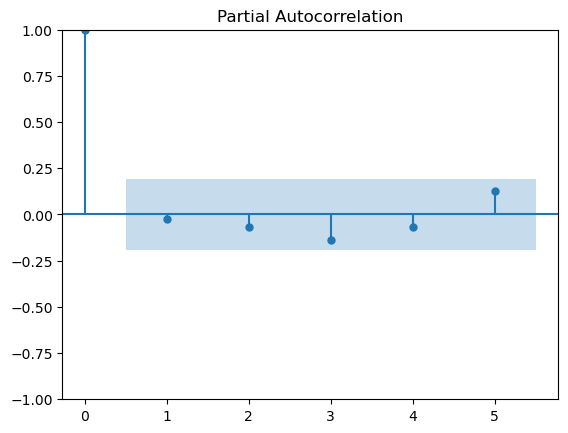

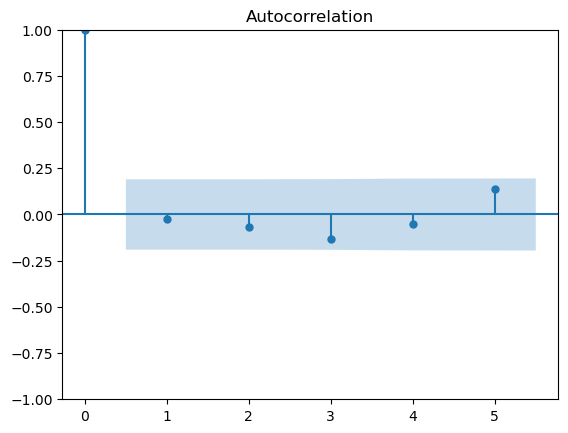

In [165]:
pacf_plot = plot_pacf(time_series['Price_Usd'] , lags=5)
acf_plot =plot_acf(time_series['Price_Usd'] , lags=5)
print(pacf_plot)
print(acf_plot)

In [184]:
arima = ARIMA(time_series['Price_Usd'] , order = (1,0,1))
arima_model = arima.fit()
arima_model.summary()

c:\Users\user\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

c:\Users\user\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.



<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:              Price_Usd   No. Observations:                  106
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -400.888
Date:                Mon, 24 Aug 2026   AIC                            809.775
Time:                        17:19:56   BIC                            820.429
Sample:                    04-23-2023   HQIC                           814.093
                         - 04-27-2025                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        349.0944      0.856    407.821      0.000     347.417     350.772
ar.L1          0.6192      0.758      0.817      0.414      -0.866       2.105
ma.L1         -0.6879      0.699     -0.985      0.325      -2.057       0.681
sigma2       112.8326     17.899      6.304      0.000      77.751     147.914
===================================================================================
Ljung-Box (L1) (Q):                   0.15   Jarque-Bera (JB):                 1.09
Prob(Q):                              0.70   Prob(JB):                         0.58
Heteroskedasticity (H):               1.66   Skew:                             0.11
Prob(H) (two-sided):                  0.14   Kurtosis:                         2.56
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

Text(0.5, 1.0, 'RSS: 11963.1948')

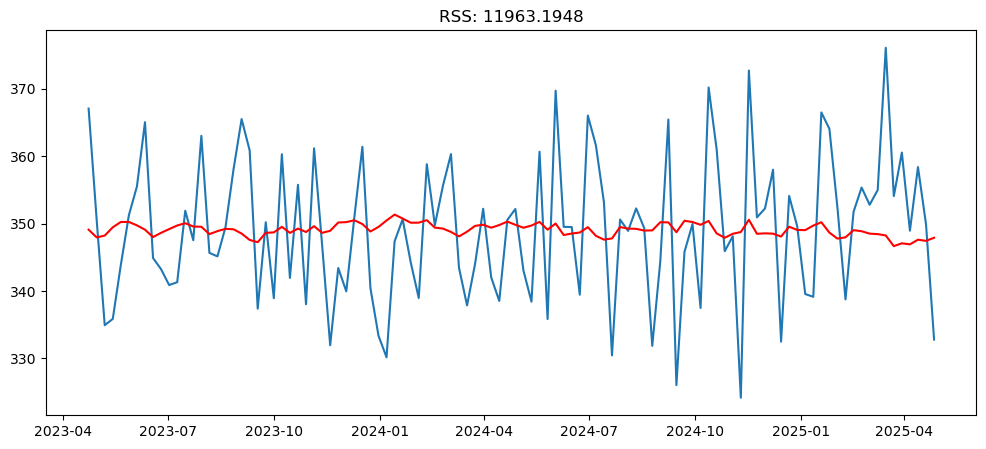

In [185]:
plt.figure(figsize = (12,5))
plt.plot(time_series['Price_Usd'] )
plt.plot(arima_model.fittedvalues , color = 'red')
plt.title("RSS: %.4f"% sum((arima_model.fittedvalues-time_series['Price_Usd'])**2))

## Prediction

<AxesSubplot:title={'center':'ARIMA Prediction of Price'}>

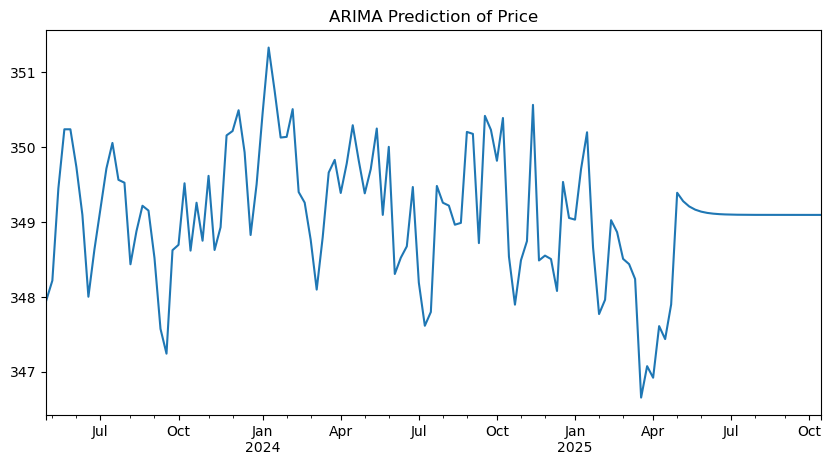

In [187]:
arima_model.predict(start = 1 , end = 130).plot(figsize = (10 ,5) , title = 'ARIMA Prediction of Price')

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
train_data = pd.read_csv('train.csv')
train_data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [4]:
sales = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Sales.csv")
products = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Products.csv")
stores = pd.read_csv("C:/Users/user/Desktop/xlsx/Maven+Electronics+Demo+Data (1)/Stores.csv")

In [5]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Order Number   62884 non-null  int64 
 1   Line Item      62884 non-null  int64 
 2   Order Date     62884 non-null  object
 3   Delivery Date  13165 non-null  object
 4   CustomerKey    62884 non-null  int64 
 5   StoreKey       62884 non-null  int64 
 6   ProductKey     62884 non-null  int64 
 7   Quantity       62884 non-null  int64 
 8   Currency Code  62884 non-null  object
dtypes: int64(6), object(3)
memory usage: 4.3+ MB


In [6]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ProductKey      2517 non-null   int64 
 1   Product Name    2517 non-null   object
 2   Brand           2517 non-null   object
 3   Color           2517 non-null   object
 4   Unit Cost USD   2517 non-null   object
 5   Unit Price USD  2517 non-null   object
 6   SubcategoryKey  2517 non-null   int64 
 7   Subcategory     2517 non-null   object
 8   CategoryKey     2517 non-null   int64 
 9   Category        2517 non-null   object
dtypes: int64(3), object(7)
memory usage: 196.8+ KB


In [7]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   StoreKey  67 non-null     int64 
 1   Country   67 non-null     object
 2   State     67 non-null     object
dtypes: int64(1), object(2)
memory usage: 1.7+ KB


In [8]:
sales['Order Date']= pd.to_datetime(sales['Order Date'])
sales['Delivery Date']= pd.to_datetime(sales['Delivery Date'])


In [13]:
modified_data = sales.merge(products , on ='ProductKey'  , how = 'left' )

total_data = modified_data.merge(stores , on = 'StoreKey' , how = 'left')
total_data.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category,Country,State
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,Contoso,White,$31.27,$68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders,Canada,Nunavut
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,A. Datum,Silver,$141.47,$427.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,$220.64,$665.94,803,Microwaves,8,Home Appliances,Online,Online
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,Contoso,Orange,$148.08,$322.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,$166.20,$326.00,301,Laptops,3,Computers,Online,Online


In [17]:
total_data['Unit Cost USD'] = total_data['Unit Cost USD'].str.replace('$' , '').str.replace(',' , '')
total_data['Unit Cost USD'] = pd.to_numeric(total_data['Unit Cost USD'])

C:\Users\user\AppData\Local\Temp\ipykernel_5692\834598459.py:1: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  total_data['Unit Cost USD'] = total_data['Unit Cost USD'].str.replace('$' , '').str.replace(',' , '')


In [18]:
total_data['Unit Price USD'] = total_data['Unit Price USD'].str.replace('$' , '').str.replace(',' , '')
total_data['Unit Price USD'] = pd.to_numeric(total_data['Unit Price USD'])

C:\Users\user\AppData\Local\Temp\ipykernel_5692\1487377436.py:1: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  total_data['Unit Price USD'] = total_data['Unit Price USD'].str.replace('$' , '').str.replace(',' , '')


In [19]:
total_data['Price_Usd'] = total_data['Unit Price USD']*total_data['Quantity']
total_data['Cost_Usd'] = total_data['Unit Cost USD']*total_data['Quantity']
total_data['Revenue'] = total_data['Price_Usd']-total_data['Cost_Usd']

In [20]:
total_data.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,...,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category,Country,State,Price_Usd,Cost_Usd,Revenue
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,...,68.00,406,Cameras & Camcorders Accessories,4,Cameras and camcorders,Canada,Nunavut,68.00,31.27,36.73
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,...,427.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,854.00,282.94,571.06
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,...,665.94,803,Microwaves,8,Home Appliances,Online,Online,665.94,220.64,445.30
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,...,322.00,402,Digital SLR Cameras,4,Cameras and camcorders,Online,Online,2254.00,1036.56,1217.44
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,...,326.00,301,Laptops,3,Computers,Online,Online,326.00,166.20,159.80


In [21]:
time_data = total_data.copy()

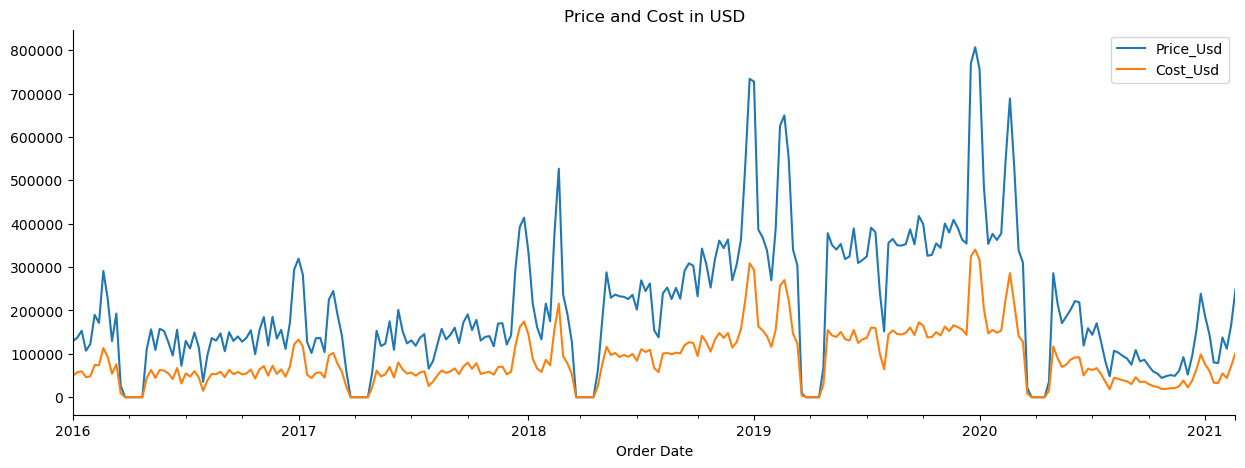

In [27]:
total_data.set_index('Order Date').resample('W').agg(Price_Usd = ('Price_Usd' , 'sum'),
                                                     Cost_Usd = ('Cost_Usd' , 'sum'),
                                                     Total_Revenue = ('Revenue' , 'sum')).plot(kind = 'line' ,
                                                                                               y = ['Price_Usd' , 'Cost_Usd'] , 
                                                                                               figsize =(15,5),
                                                                                               title = 'Price and Cost in USD')
sns.despine()

In [29]:
total_data.set_index('Order Date').resample('W').agg(Price_Usd = ('Price_Usd' , 'sum'),
                                                     Cost_Usd = ('Cost_Usd' , 'sum'),
                                                     Total_Revenue = ('Revenue' , 'sum')).loc['2016-02':'2016-04']

,Price_Usd,Cost_Usd,Total_Revenue
Order Date,,,
2016-02-07,189963.56,74242.98,115720.58
2016-02-14,171402.68,73835.02,97567.66
2016-02-21,291115.94,113251.53,177864.41
2016-02-28,227944.04,93296.59,134647.45
2016-03-06,129295.88,54210.52,75085.36
2016-03-13,192844.36,76077.44,116766.92
2016-03-20,26939.20,9361.84,17577.36
2016-03-27,0.00,0.00,0.00
2016-04-03,0.00,0.00,0.00


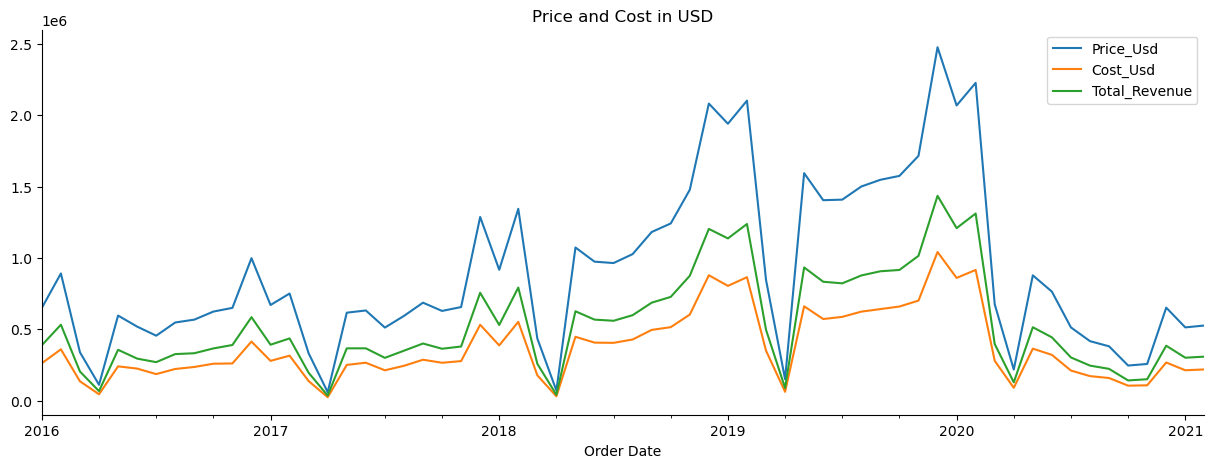

In [40]:
total_data.set_index('Order Date').resample('M').agg(Price_Usd = ('Price_Usd' , 'sum'),
                                                     Cost_Usd = ('Cost_Usd' , 'sum'),
                                                     Total_Revenue = ('Revenue' , 'sum')).plot(kind = 'line' ,
                                                                                               y = ['Price_Usd' , 'Cost_Usd','Total_Revenue'] , 
                                                                                               figsize =(15,5),
                                                                                               title = 'Price and Cost in USD')
sns.despine()

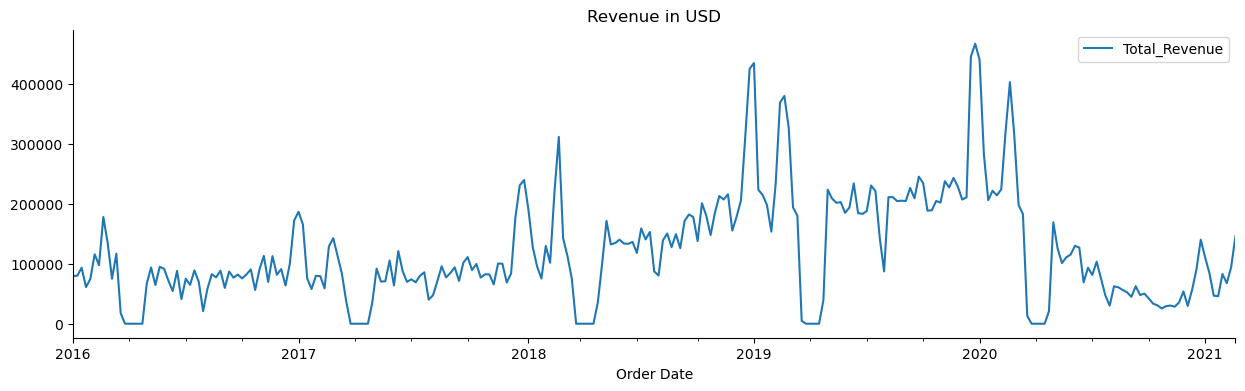

In [43]:
total_data.set_index('Order Date').resample('W').agg(Price_Usd = ('Price_Usd' , 'sum'),
                                                     Cost_Usd = ('Cost_Usd' , 'sum'),
                                                     Total_Revenue = ('Revenue' , 'sum')).plot(kind = 'line' ,
                                                                                               y = 'Total_Revenue' , 
                                                                                               figsize =(15,4),
                                                                                               title = 'Revenue in USD')
                                                     
sns.despine()

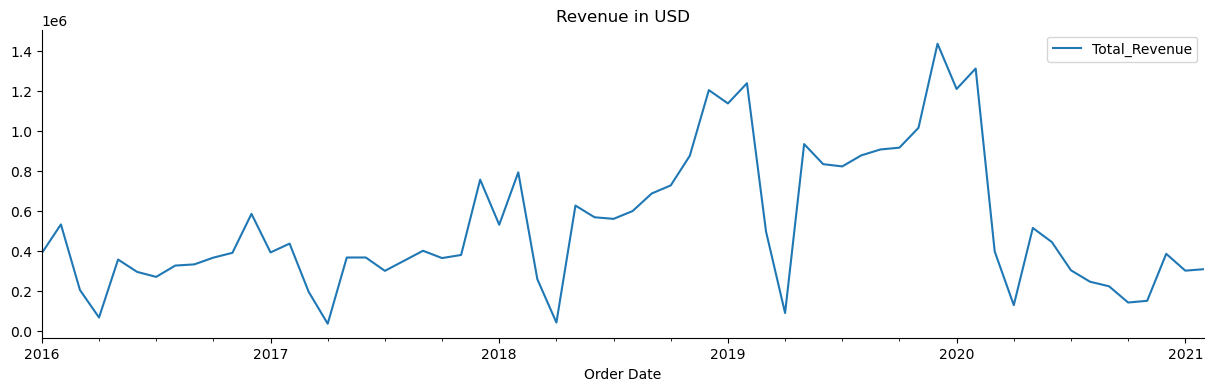

In [45]:
total_data.set_index('Order Date').resample('M').agg(Price_Usd = ('Price_Usd' , 'sum'),
                                                     Cost_Usd = ('Cost_Usd' , 'sum'),
                                                     Total_Revenue = ('Revenue' , 'sum')).plot(kind = 'line' ,
                                                                                               y = 'Total_Revenue' , 
                                                                                               figsize =(15,4),
                                                                                               title = 'Revenue in USD')
                                                     
sns.despine()

In [48]:
total_data.columns = total_data.columns.str.replace(' ' , '_')

In [49]:
total_data.columns

Index(['Order_Number', 'Line_Item', 'Order_Date', 'Delivery_Date',
       'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency_Code',
       'Product_Name', 'Brand', 'Color', 'Unit_Cost_USD', 'Unit_Price_USD',
       'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category', 'Country',
       'State', 'Price_Usd', 'Cost_Usd', 'Revenue'],
      dtype='object')

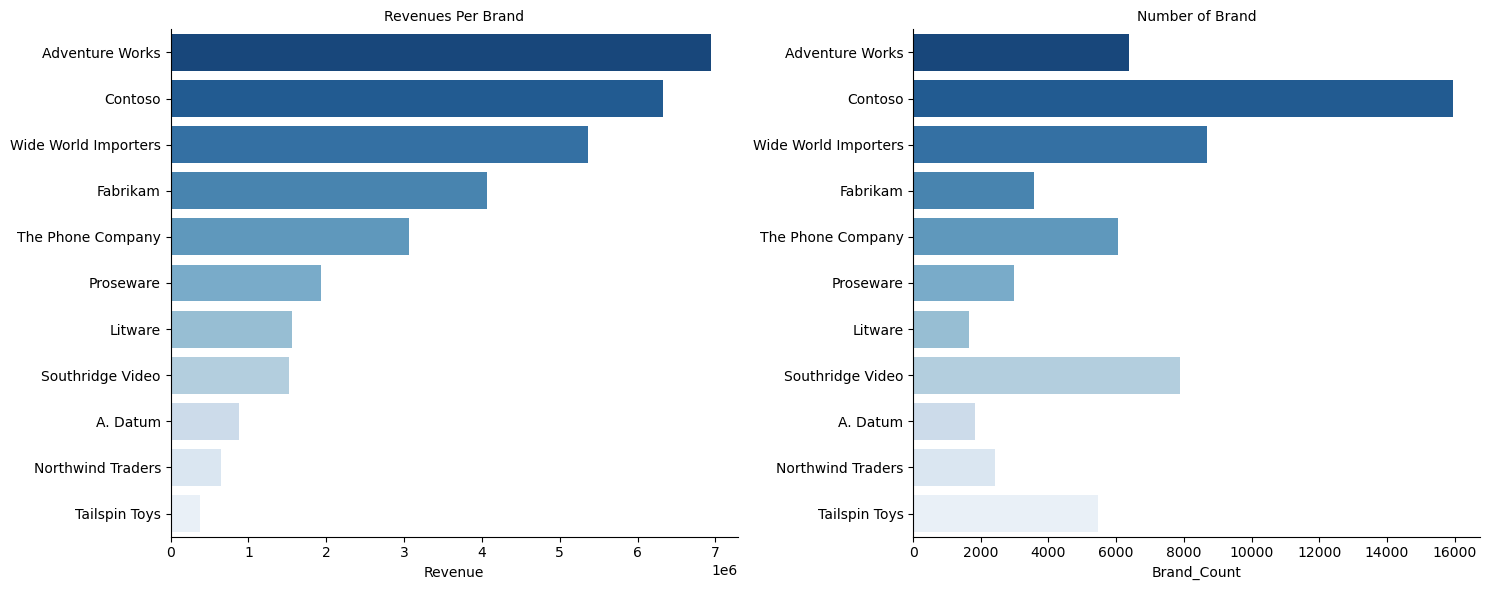

In [64]:
grp = total_data.groupby('Brand').agg(Brand_Count= ('Brand' , 'count'),
                                Revenue = ('Revenue' , 'sum')).sort_values(by = 'Revenue' , ascending = False).reset_index()
fig, (ax1 , ax2) = plt.subplots(1,2 , figsize = (15,6))
sns.despine()
sns.barplot(data = grp , x = 'Revenue' , y = 'Brand' , palette = 'Blues_r' , ax = ax1)
ax1.set_title('Revenues Per Brand' , fontsize = 10)
ax1.set_ylabel('')
sns.barplot(data = grp , x = 'Brand_Count' , y = 'Brand' , palette = 'Blues_r' , ax = ax2)
ax2.set_title('Number of Brand' , fontsize = 10)
ax2.set_ylabel('')

plt.tight_layout()

# NetFlix Data

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
netflix_data = pd.read_csv('netflix_titles.csv')
netflix_data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
netflix_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [4]:
netflix_data.shape

(8807, 12)

In [5]:
netflix_data.duplicated().sum()

0

In [6]:
netflix_data.isna().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [7]:
netflix_data.type.value_counts(dropna = False)

Movie      6131
TV Show    2676
Name: type, dtype: int64

In [9]:
netflix_data.type.value_counts(dropna = True)

Movie      6131
TV Show    2676
Name: type, dtype: int64

In [10]:
netflix_data.rating.value_counts()

TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: rating, dtype: int64

In [11]:
shifted_rows = netflix_data[netflix_data['rating'].isin(['74 min' , '84 min' , '66 min'])]
shifted_rows

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [12]:
shift_mask = netflix_data['rating'].isin(['74 min' , '84 min' , '66 min'])

In [13]:
shift_mask.value_counts()

False    8804
True        3
Name: rating, dtype: int64

In [14]:
netflix_data.loc[shift_mask , 'duration'] = netflix_data.loc[shift_mask , 'rating']
netflix_data.loc[shift_mask , 'rating'] = None

In [15]:
netflix_data.loc[shift_mask ]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,None,74 min,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,None,84 min,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,None,66 min,Movies,The comic puts his trademark hilarious/thought...


In [16]:
netflix_data.rating.value_counts()

TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: rating, dtype: int64

In [17]:
netflix_data.groupby('type')['rating'].value_counts()

type     rating  
Movie    TV-MA       2062
         TV-14       1427
         R            797
         TV-PG        540
         PG-13        490
         PG           287
         TV-Y7        139
         TV-Y         131
         TV-G         126
         NR            75
         G             41
         TV-Y7-FV       5
         NC-17          3
         UR             3
TV Show  TV-MA       1145
         TV-14        733
         TV-PG        323
         TV-Y7        195
         TV-Y         176
         TV-G          94
         NR             5
         R              2
         TV-Y7-FV       1
Name: rating, dtype: int64

In [20]:
netflix_data['rating'].fillna(netflix_data['rating'].mode()[0] , inplace = True)

In [21]:
netflix_data['rating'].isna().sum()

0

In [22]:
for col in ['director' , 'cast' , 'country']:
    netflix_data[col] = netflix_data[col].fillna('Unknown')

In [24]:
netflix_data[['director' , 'cast' , 'country']].isna().sum()

director    0
cast        0
country     0
dtype: int64

In [25]:
netflix_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      8807 non-null   object
 4   cast          8807 non-null   object
 5   country       8807 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8807 non-null   object
 9   duration      8807 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [28]:
netflix_data['date_added'] = netflix_data['date_added'].str.strip()

In [29]:
netflix_data['date_added'] = pd.to_datetime(netflix_data['date_added'] , format = '%B %d, %Y')

In [30]:
netflix_data['date_added'].head()

0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[ns]

In [32]:
netflix_data[netflix_data['date_added'].isna()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,Unknown,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,Unknown,Anthony Bourdain,United States,NaT,2018,TV-PG,5 Seasons,Docuseries,This CNN original series has chef Anthony Bour...
6795,s6796,TV Show,Frasier,Unknown,"Kelsey Grammer, Jane Leeves, David Hyde Pierce...",United States,NaT,2003,TV-PG,11 Seasons,"Classic & Cult TV, TV Comedies",Frasier Crane is a snooty but lovable Seattle ...
6806,s6807,TV Show,Friends,Unknown,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaT,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...
6901,s6902,TV Show,Gunslinger Girl,Unknown,"Yuuka Nanri, Kanako Mitsuhashi, Eri Sendai, Am...",Japan,NaT,2008,TV-14,2 Seasons,"Anime Series, Crime TV Shows","On the surface, the Social Welfare Agency appe..."
7196,s7197,TV Show,Kikoriki,Unknown,Igor Dmitriev,Unknown,NaT,2010,TV-Y,2 Seasons,Kids' TV,A wacky rabbit and his gang of animal pals hav...
7254,s7255,TV Show,La Familia P. Luche,Unknown,"Eugenio Derbez, Consuelo Duval, Luis Manuel Áv...",United States,NaT,2012,TV-14,3 Seasons,"International TV Shows, Spanish-Language TV Sh...","This irreverent sitcom featues Ludovico, Feder..."
7406,s7407,TV Show,Maron,Unknown,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaT,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
7847,s7848,TV Show,Red vs. Blue,Unknown,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaT,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
8182,s8183,TV Show,The Adventures of Figaro Pho,Unknown,"Luke Jurevicius, Craig Behenna, Charlotte Haml...",Australia,NaT,2015,TV-Y7,2 Seasons,"Kids' TV, TV Comedies","Imagine your worst fears, then multiply them: ..."


In [33]:
netflix_data['year_added'] = netflix_data['date_added'].dt.year
netflix_data['month_added'] = netflix_data['date_added'].dt.month

In [34]:
netflix_data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0


In [35]:
netflix_data.to_excel('netflix_data_cleaned.xlsx' , index = False)
